# DSCO 2026 — Prediksi Mahasiswa Berisiko (`at_risk`)

**Tugas:** klasifikasi biner — memprediksi apakah seorang mahasiswa berisiko (`at_risk = 1`) dari data demografi, asesmen awal, dan aktivitas belajar daring 4 minggu pertama.
**Metrik:** F1 score.

**Isi notebook**

1. Setup
2. Exploratory Data Analysis (EDA)
3. Preprocessing
4. Pemilihan model
5. Evaluasi model
6. Prediksi data test & file submission
7. Insight preskriptif

**Kepatuhan aturan:** hanya memakai `train.csv` dan `test.csv` dari panitia, tanpa data eksternal, tanpa AutoML, tanpa model pre-trained, tanpa mengubah label. Semua seed dikunci agar hasil dapat direproduksi dengan *Run All*.

## 1. Setup

In [1]:
import os, time, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score, roc_auc_score, precision_score, recall_score, confusion_matrix, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier

SEED = 42
N_FOLDS = 5
N_JOBS = 4
np.random.seed(SEED)

SUBMISSION_NO = 5  # nomor urut submission; nama file: submission_<nomor>.csv
SEEDS = [42, 7, 2026]  # model boosting dilatih ulang dengan beberapa seed lalu dirata-ratakan

# CSV dibaca dari folder yang sama dengan notebook (sesuai ketentuan panitia).
# Fallback ke ../data/raw/ hanya untuk struktur folder kerja tim.
DATA_DIR = "" if os.path.exists("train.csv") else "../data/raw/"
OUT_DIR = "../submissions/" if os.path.isdir("../submissions") else ""

C0, C1, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": "#52514e", "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left", "font.size": 9,
})

In [2]:
train = pd.read_csv(DATA_DIR + "train.csv")
test = pd.read_csv(DATA_DIR + "test.csv")
sample_sub = pd.read_csv(DATA_DIR + "sample_submission.csv")

TARGET = "at_risk"
print("train:", train.shape, "| test:", test.shape, "| sample_submission:", sample_sub.shape)
train.head()

train: (26086, 64) | test: (6502, 63) | sample_submission: (6502, 2)


,id,code_module,code_presentation,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,...,week4_interactions,interaction_trend,early_interactions,late_interactions,late_to_early_interactions_ratio,avg_interactions_per_active_day,active_weeks,avg_interactions_per_active_week,activity_span_days,at_risk
0,1,M01,P12,M,Region1,HE Qualification,90-100%,55<=,0,240,...,0,-46.9,203,100,0.492611,43.285714,3,101.00,18,0
1,2,M01,P12,F,Region6,HE Qualification,20-30%,35-55,0,60,...,125,-17.9,241,162,0.672199,33.583333,4,100.75,28,0
2,3,M01,P12,F,region2,A Level,30-40%,35-55,0,60,...,0,-39.3,179,0,0.000000,29.833333,2,89.50,8,1
3,4,M01,P12,F,Region 10,A Level,50-60%,35-55,0,60,...,41,1.1,176,149,0.846591,19.117647,4,81.25,27,0
4,5,M01,P12,F,Region9,Lower Than A Level,50-60%,0-35,0,60,...,58,-8.8,177,95,0.536723,17.000000,4,68.00,25,0


## 2. Exploratory Data Analysis

### 2.1 Struktur data dan target

Tipe kolom: {dtype('int64'): 40, dtype('float64'): 16, <StringDtype(storage='python', na_value=nan)>: 8}
NaN train: 0 | NaN test: 0
Baris duplikat penuh (tanpa id): 4
Rentang id train: 1 - 26091 | test: 26092 - 32593

Distribusi target:
         jumlah  proporsi
at_risk                  
0         12333    0.4728
1         13753    0.5272


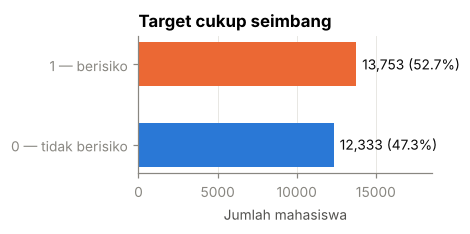

In [3]:
print("Tipe kolom:", train.dtypes.value_counts().to_dict())
print("NaN train:", int(train.isna().sum().sum()), "| NaN test:", int(test.isna().sum().sum()))
print("Baris duplikat penuh (tanpa id):", int(train.drop(columns="id").duplicated().sum()))
print("Rentang id train:", train.id.min(), "-", train.id.max(), "| test:", test.id.min(), "-", test.id.max())

vc = train[TARGET].value_counts().sort_index()
print("\nDistribusi target:")
print(pd.DataFrame({"jumlah": vc, "proporsi": (vc / len(train)).round(4)}))

fig, ax = plt.subplots(figsize=(4.2, 2.2))
bars = ax.barh(["0 — tidak berisiko", "1 — berisiko"], vc.values, color=[C0, C1], height=0.55)
ax.bar_label(bars, labels=[f"{v:,} ({v/len(train):.1%})" for v in vc.values], padding=4, color=INK)
ax.set_xlim(0, vc.max() * 1.35); ax.grid(axis="y", visible=False)
ax.set_title("Target cukup seimbang"); ax.set_xlabel("Jumlah mahasiswa")
plt.tight_layout(); plt.show()

Target hampir seimbang (≈53% berisiko), sehingga tidak diperlukan resampling. Karena metriknya F1 untuk kelas positif, **threshold keputusan** perlu dioptimalkan — tidak otomatis 0,5.

### 2.2 Kualitas data kategorikal

In [4]:
cat_cols = train.select_dtypes("object").columns.tolist()
rows = []
for c in cat_cols:
    only_test = sorted(set(test[c]) - set(train[c]))
    rows.append({"kolom": c, "n_unik_train": train[c].nunique(), "n_unik_test": test[c].nunique(), "hanya_di_test": only_test})
display(pd.DataFrame(rows))

print("region            :", sorted(train.region.unique()))
print("highest_education :", sorted(train.highest_education.unique()), "| test:", sorted(test.highest_education.unique()))
print("imd_band          :", sorted(train.imd_band.unique()))

,kolom,n_unik_train,n_unik_test,hanya_di_test
0,code_module,7,8,[GGG]
1,code_presentation,4,4,[]
2,gender,2,2,[]
3,region,13,13,[]
4,highest_education,5,5,[A level]
5,imd_band,11,11,[]
6,age_band,3,3,[]
7,disability,2,2,[]


region            : ['Region 10', 'Region 3', 'Region 4', 'Region1', 'Region11', 'Region12', 'Region13', 'Region5', 'Region6', 'Region7', 'Region8', 'Region9', 'region2']
highest_education : ['-', 'A Level', 'HE Qualification', 'Lower Than A Level', 'Post Graduate Qualification'] | test: ['-', 'A level', 'HE Qualification', 'Lower Than A Level', 'Post Graduate Qualification']
imd_band          : ['-', '0-10%', '20-30%', '30-40%', '40-50%', '50-60%', '60-70%', '70-80%', '80-90%', '90-100%', '?']


Temuan:

- **Penulisan tidak konsisten** — `region` (`Region1`, `region2`, `Region 3`) dan `highest_education` (`A Level` di train, `A level` di test). Tanpa dinormalkan, model akan menganggap `A level` sebagai kategori baru.
- **Missing tersamar** — `imd_band` berisi `-` dan `?`, `highest_education` berisi `-`. Nilainya dibiarkan sebagai kategori sendiri karena "tidak diisi" bisa informatif.
- **`code_module = GGG` hanya ada di test.** Diperiksa di bawah.

In [5]:
print("Train — modul x presentasi"); display(pd.crosstab(train.code_module, train.code_presentation))
print("Test — modul x presentasi"); display(pd.crosstab(test.code_module, test.code_presentation))

sig = lambda d: d.groupby("code_module").apply(lambda g: sorted(set(zip(g.code_presentation, g.module_presentation_length))))
print("Pasangan (presentasi, panjang modul):")
print("  GGG (test) :", sig(test)["GGG"])
print("  M07 (train):", sig(train)["M07"])
ratio = (test.code_module.value_counts() / train.code_module.value_counts()).round(3)
print("\nRasio jumlah baris test/train per modul:"); print(ratio.to_string())
print("Rasio M07 jika GGG digabung:", round(((test.code_module.isin(["M07", "GGG"])).sum()) / (train.code_module == "M07").sum(), 3))

is_a = lambda s: s.str.lower().eq("a level")
print("\nProporsi pendidikan 'A Level':")
print("  M07 train        :", round(is_a(train.loc[train.code_module == "M07", "highest_education"]).mean(), 3))
print("  M07 test         :", round(is_a(test.loc[test.code_module == "M07", "highest_education"]).mean(), 3))
print("  GGG test         :", round(is_a(test.loc[test.code_module == "GGG", "highest_education"]).mean(), 3))
print("  M07 + GGG (test) :", round(is_a(test.loc[test.code_module.isin(["M07", "GGG"]), "highest_education"]).mean(), 3))

Train — modul x presentasi


code_presentation,P11,P12,P21,P22
code_module,,,,
M01,0,306,0,296
M02,1414,1819,1281,1854
M03,0,0,1596,1972
M04,1285,1823,1168,2027
M05,0,845,554,944
M06,1054,1567,990,1455
M07,0,756,626,454


Test — modul x presentasi


code_presentation,P11,P12,P21,P22
code_module,,,,
GGG,0,124,146,102
M01,0,77,0,69
M02,353,418,328,437
M03,0,0,340,526
M04,329,460,332,482
M05,0,208,140,244
M06,249,371,238,348
M07,0,71,61,49


Pasangan (presentasi, panjang modul):
  GGG (test) : [('P12', 261), ('P21', 241), ('P22', 269)]
  M07 (train): [('P12', 261), ('P21', 241), ('P22', 269)]

Rasio jumlah baris test/train per modul:
code_module
GGG      NaN
M01    0.243
M02    0.241
M03    0.243
M04    0.254
M05    0.253
M06    0.238
M07    0.099
Rasio M07 jika GGG digabung: 0.301

Proporsi pendidikan 'A Level':
  M07 train        : 0.346
  M07 test         : 1.0
  GGG test         : 0.0
  M07 + GGG (test) : 0.327


Tiga bukti bahwa `GGG` sebenarnya adalah `M07` yang belum disandikan:

1. Kombinasi presentasi dan panjang modulnya **persis sama** dengan `M07`.
2. `M07` adalah satu-satunya modul yang porsi test-nya jauh di bawah modul lain (≈0,10 dibanding ≈0,25); setelah `GGG` digabung, rasionya kembali wajar.
3. Di data test, baris `M07` **seluruhnya** berpendidikan `A level` dan baris `GGG` **tidak ada** yang `A level`. Jika digabung, proporsi `A level`-nya kembali sama dengan `M07` di train.

Karena itu `GGG` dipetakan ke `M07` pada preprocessing.

### 2.2b Urutan `id` dan kode modul yang terselip

In [6]:
t = train.sort_values("id")
blk = t.code_module + "_" + t.code_presentation
runs = (t.assign(blok=blk, seg=(blk != blk.shift()).cumsum())
         .groupby("seg").agg(blok=("blok", "first"), id_awal=("id", "min"), id_akhir=("id", "max"), n=("id", "size")))
print("Blok modul-presentasi di train:", blk.nunique(), "| segmen id berurutan:", len(runs))
display(runs.iloc[17:])

r = runs[runs.blok == "M04_P22"].iloc[-1]
odd = train.id.between(r.id_awal, r.id_akhir)
grp = {f"{int(odd.sum())} baris terselip (tertulis M04)": train[odd],
       "M07_P22": train[(train.code_module == "M07") & (train.code_presentation == "P22")],
       "M04_P22 lainnya": train[(train.code_module == "M04") & (train.code_presentation == "P22") & ~odd]}
cols = ["module_presentation_length", "studied_credits", "has_score", "unique_sites", "unique_activity_types", "interaction_volume", TARGET]
pd.DataFrame({k: v[cols].mean() for k, v in grp.items()}).round(2)

Blok modul-presentasi di train: 22 | segmen id berurutan: 26


,blok,id_awal,id_akhir,n
seg,,,,
18,M04_P21,21060,22227,1168
19,M04_P22,22228,24110,1883
20,M07_P12,24111,24111,1
21,M05_P12,24112,24112,1
22,M07_P12,24113,24867,755
23,M07_P21,24868,25493,626
24,M07_P22,25494,25936,443
25,M04_P22,25937,26080,144
26,M07_P22,26081,26091,11


,144 baris terselip (tertulis M04),M07_P22,M04_P22 lainnya
module_presentation_length,269.00,269.00,269.00
studied_credits,33.12,33.30,92.67
has_score,0.00,0.00,0.70
unique_sites,12.28,12.64,33.58
unique_activity_types,4.85,5.13,8.61
interaction_volume,98.48,108.84,447.09
at_risk,0.44,0.41,0.52


Baris train tersusun per blok modul-presentasi menurut `id`: 22 blok seharusnya menjadi 22 segmen, tetapi ada 26. Penyebabnya dua sisipan:

- **144 baris bertuliskan `M04_P22` berada di tengah blok `M07_P22`.** Cirinya sama dengan `M07_P22` dan jauh berbeda dari `M04_P22` yang lain (SKS ≈33 dibanding ≈93, belum ada nilai asesmen, jumlah situs dan jenis aktivitas jauh lebih sedikit).
- **1 baris bertuliskan `M05_P12` berada di dalam blok `M07_P12`**, dengan panjang modul 261 hari (milik `M07_P12`; `M05_P12` panjangnya 268).

Jadi 145 baris ini adalah mahasiswa `M07` yang kode modulnya tertulis salah — sejenis dengan `GGG` di data test. Kode modulnya diperbaiki pada preprocessing. Data test tidak memiliki sisipan seperti ini.

### 2.3 Kolom numerik

In [7]:
num_cols = [c for c in train.columns if c not in cat_cols + ["id", TARGET]]
desc = train[num_cols].describe().T[["min", "50%", "max"]]
desc["n_unik"] = train[num_cols].nunique()
const_cols = desc.index[desc.n_unik == 1].tolist()
print("Kolom konstan:", const_cols)

print("\nNilai paling sering muncul saat has_score = 0 (nilai asesmen belum ada):")
for c in ["avg_score", "score_Assessment_1", "avg_submission_delay"]:
    top = train.loc[train.has_score == 0, c].value_counts(normalize=True).head(1)
    print(f"  {c:22s} -> {top.index[0]} ({top.iloc[0]:.1%} baris)")
desc.head(12)

Kolom konstan: ['submitted_Assessment_2', 'submitted_Assessment_1']

Nilai paling sering muncul saat has_score = 0 (nilai asesmen belum ada):
  avg_score              -> 77.0 (100.0% baris)
  score_Assessment_1     -> 70 (100.0% baris)
  avg_submission_delay   -> -1.0 (99.9% baris)


,min,50%,max,n_unik
num_of_prev_attempts,0.0,0.0,6.0,7
studied_credits,30.0,60.0,655.0,58
module_presentation_length,234.0,262.0,269.0,7
registration_days_from_start,-322.0,-57.0,167.0,322
assessments_due_total,1.0,1.0,2.0,2
assessments_due_Assessment_1,0.0,0.0,1.0,2
assessments_due_Assessment_2,0.0,1.0,1.0,2
submitted_count,1.0,1.0,2.0,2
late_submission_count,0.0,0.0,2.0,3
avg_score,0.0,77.0,100.0,163


- `submitted_Assessment_1` dan `submitted_Assessment_2` konstan → dibuang.
- Saat `has_score = 0`, kolom nilai dan keterlambatan terisi satu angka yang sama (hasil imputasi panitia). Karena itu `has_score` dan `no_submission_by_cutoff` penting sebagai penanda; model pohon dapat memanfaatkan interaksi ini dengan sendirinya.

### 2.4 Hubungan fitur dengan target

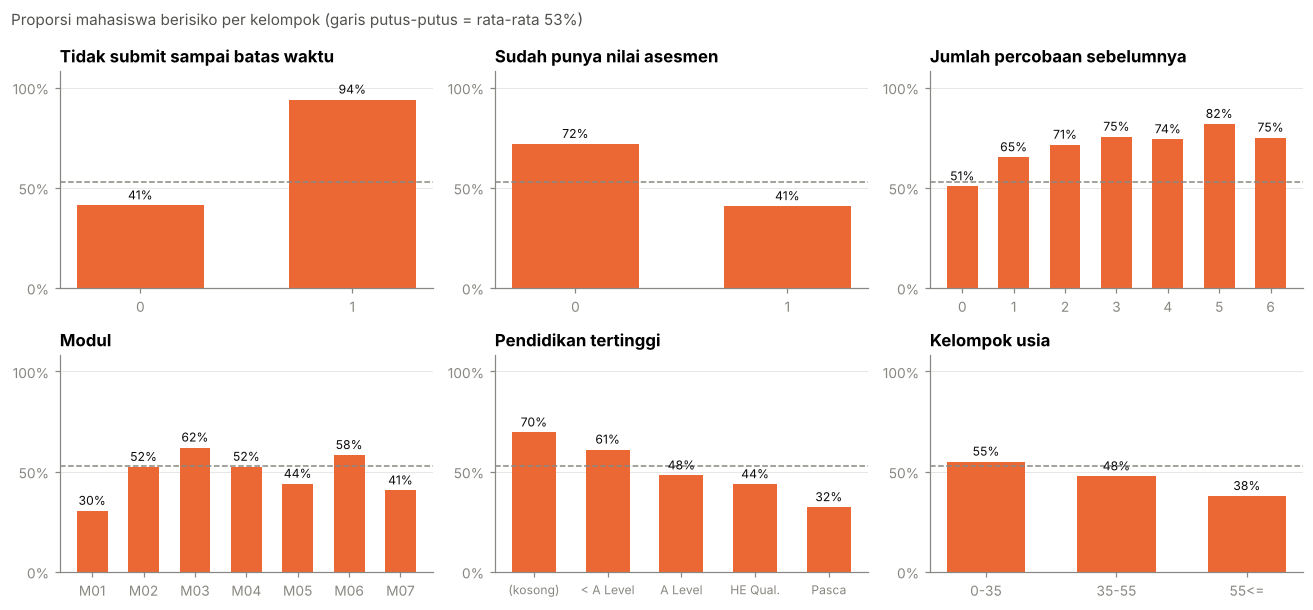

In [8]:
def rate_plot(ax, col, title, order=None):
    g = train.groupby(col)[TARGET].agg(["mean", "size"])
    if order is not None: g = g.reindex(order)
    b = ax.bar(g.index.astype(str), g["mean"], color=C1, width=0.6)
    ax.bar_label(b, labels=[f"{m:.0%}" for m in g["mean"]], padding=2, color=INK, fontsize=8)
    ax.axhline(train[TARGET].mean(), color=MUTED, lw=1, ls="--")
    ax.set_ylim(0, 1.08); ax.set_title(title); ax.grid(axis="x", visible=False)
    ax.set_yticks([0, .5, 1]); ax.set_yticklabels(["0%", "50%", "100%"])

fig, axes = plt.subplots(2, 3, figsize=(12, 5.6))
rate_plot(axes[0, 0], "no_submission_by_cutoff", "Tidak submit sampai batas waktu")
rate_plot(axes[0, 1], "has_score", "Sudah punya nilai asesmen")
rate_plot(axes[0, 2], "num_of_prev_attempts", "Jumlah percobaan sebelumnya")
rate_plot(axes[1, 0], "code_module", "Modul")
rate_plot(axes[1, 1], "highest_education", "Pendidikan tertinggi", order=["-", "Lower Than A Level", "A Level", "HE Qualification", "Post Graduate Qualification"])
axes[1, 1].set_xticklabels(["(kosong)", "< A Level", "A Level", "HE Qual.", "Pasca"], fontsize=8)
rate_plot(axes[1, 2], "age_band", "Kelompok usia")
fig.suptitle("Proporsi mahasiswa berisiko per kelompok (garis putus-putus = rata-rata 53%)", x=0.01, ha="left", fontsize=10, color="#52514e")
plt.tight_layout(); plt.show()

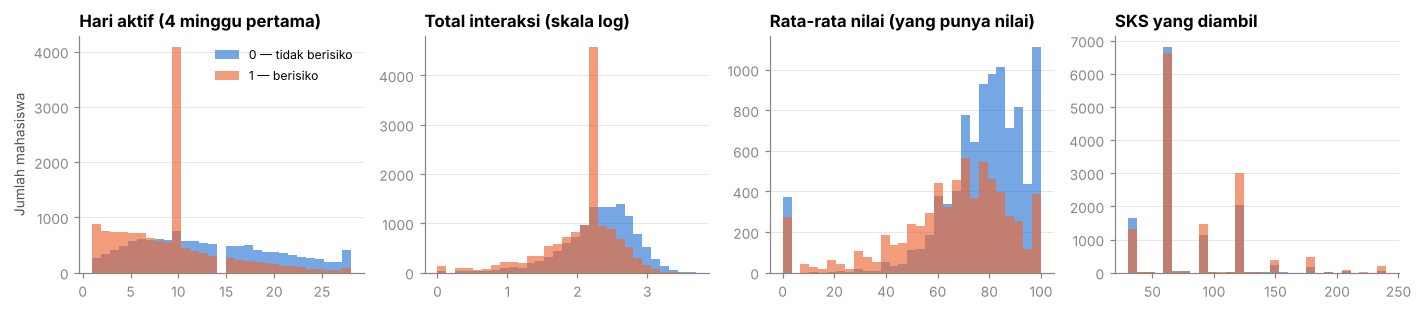

In [9]:
feats = ["active_days", "interaction_volume", "avg_score", "studied_credits"]
titles = ["Hari aktif (4 minggu pertama)", "Total interaksi (skala log)", "Rata-rata nilai (yang punya nilai)", "SKS yang diambil"]
fig, axes = plt.subplots(1, 4, figsize=(13, 2.9))
for ax, c, t in zip(axes, feats, titles):
    d = train[train.has_score == 1] if c == "avg_score" else train
    v = np.log10(d[c]) if c == "interaction_volume" else d[c].clip(upper=d[c].quantile(.99))
    bins = np.linspace(v.min(), v.max(), 30)
    ax.hist(v[d[TARGET] == 0], bins=bins, color=C0, alpha=.65, label="0 — tidak berisiko")
    ax.hist(v[d[TARGET] == 1], bins=bins, color=C1, alpha=.65, label="1 — berisiko")
    ax.set_title(t); ax.grid(axis="x", visible=False)
axes[0].legend(frameon=False, fontsize=8); axes[0].set_ylabel("Jumlah mahasiswa")
plt.tight_layout(); plt.show()

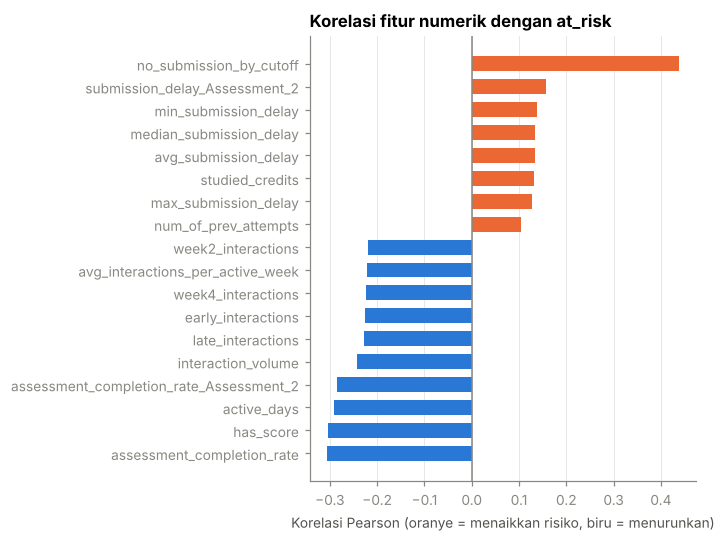

In [10]:
corr = train[[c for c in num_cols if c not in const_cols] + [TARGET]].corr()[TARGET].drop(TARGET).sort_values()
top = pd.concat([corr.head(10), corr.tail(8)])
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.barh(top.index, top.values, color=[C0 if v < 0 else C1 for v in top.values], height=0.65)
ax.axvline(0, color=MUTED, lw=1); ax.grid(axis="y", visible=False)
ax.set_title("Korelasi fitur numerik dengan at_risk"); ax.set_xlabel("Korelasi Pearson (oranye = menaikkan risiko, biru = menurunkan)")
plt.tight_layout(); plt.show()

Ringkasan EDA:

- Sinyal terkuat adalah **perilaku pada 4 minggu pertama**: tidak mengumpulkan asesmen sampai batas waktu (94% berisiko), sedikit hari aktif, dan sedikit interaksi.
- Riwayat akademik ikut berpengaruh: makin banyak percobaan sebelumnya dan makin banyak SKS, makin tinggi risikonya.
- Risiko berbeda antarmodul (30%–62%), jadi `code_module` perlu dipertahankan.
- Banyak kolom nilai/keterlambatan saling redundan (`avg = median = max = min` ketika hanya ada satu asesmen) — tidak masalah untuk model pohon.

## 3. Preprocessing

### 3.1 Pembersihan

Langkah yang dilakukan, semuanya berasal dari temuan EDA:

1. `code_module`: `GGG` → `M07`.
2. `region`: hapus spasi dan samakan kapitalisasi.
3. `highest_education`: samakan kapitalisasi; `-` dijadikan kategori `Unknown`.
4. `imd_band`: `-` dan `?` dibiarkan sebagai kategori tersendiri.
5. **Kode modul yang terselip** (2.2b): segmen yang diapit dua segmen dari modul lain pada presentasi yang sama mengikuti modul pengapitnya. Yang berubah hanya kolom fitur `code_module` pada 145 baris train.
6. **Nilai hasil imputasi panitia** dikembalikan menjadi "tidak ada" (bagian 3.1b), dan `imd_band`, `highest_education`, `age_band` diberi versi berurutan (ordinal).
7. Buang dua kolom konstan. `id` tidak dipakai sebagai fitur mentah (rentangnya berbeda antara train dan test), tetapi **urutannya** dipakai di bagian 3.2.
8. Label **tidak** diubah dan tidak ada baris yang dibuang.

Fitur turunan biasa (rasio interaksi, peringkat dalam modul-presentasi, jumlah minggu tanpa aktivitas) sudah dicoba dan tidak menaikkan skor validasi silang, karena kolom yang tersedia sudah berupa agregat dan model pohon sudah menangkapnya. Tambahan yang terbukti berguna adalah penanganan nilai imputasi (3.1b) dan fitur tautan mahasiswa mengulang (3.2).

In [11]:
DROP_COLS = ["id", "submitted_Assessment_1", "submitted_Assessment_2"]

def clean(df):
    df = df.copy()
    df["code_module"] = df["code_module"].replace({"GGG": "M07"})
    df["region"] = df["region"].str.replace(" ", "", regex=False).str.capitalize()
    df["highest_education"] = df["highest_education"].str.title().replace({"-": "Unknown"})
    return df

def id_runs(df):
    # segmen = deretan id berurutan dengan blok modul-presentasi yang sama
    blk = (df["code_module"] + "_" + df["code_presentation"]).values
    order = np.argsort(df["id"].values, kind="stable")
    b = blk[order]
    seg = np.empty(len(df), dtype=int)
    seg[order] = np.r_[0, np.cumsum(b[1:] != b[:-1])]
    return seg

def fix_misplaced_module(df):
    # segmen yang terselip di antara dua segmen modul lain (presentasi sama) -> ikut modul pengapitnya
    df = df.copy()
    seg = id_runs(df)
    r = (pd.DataFrame({"seg": seg, "id": df["id"].values, "mod": df["code_module"].values, "pres": df["code_presentation"].values})
         .groupby("seg").agg(mod=("mod", "first"), pres=("pres", "first"), id_awal=("id", "min"), id_akhir=("id", "max"), n=("id", "size"))
         .sort_values("id_awal"))
    mods, pres = r["mod"].values.copy(), r["pres"].values
    for i in range(1, len(r) - 1):
        if mods[i - 1] == mods[i + 1] != mods[i] and pres[i - 1] == pres[i] == pres[i + 1]:
            mods[i] = mods[i - 1]
    r["mod_baru"] = mods
    df["code_module"] = pd.Series(seg).map(r["mod_baru"]).values
    return df, r[r["mod"] != r["mod_baru"]]

y = train[TARGET].values
n_train = len(train)
full_raw = clean(pd.concat([train.drop(columns=TARGET), test], ignore_index=True))
full_id, moved = fix_misplaced_module(full_raw)
N = len(full_id)
is_test = np.arange(N) >= n_train
print("Baris:", N, "| kategori region:", full_id.region.nunique(), "| modul:", sorted(full_id.code_module.unique()))
print("Baris yang kode modulnya diperbaiki:", int((full_id.code_module != full_raw.code_module).sum()), "| di test:", int((full_id.code_module != full_raw.code_module)[n_train:].sum()))
moved

Baris: 32588 | kategori region: 13 | modul: ['M01', 'M02', 'M03', 'M04', 'M05', 'M06', 'M07']
Baris yang kode modulnya diperbaiki: 145 | di test: 0


,mod,pres,id_awal,id_akhir,n,mod_baru
seg,,,,,,
20,M05,P12,24112,24112,1,M07
24,M04,P22,25937,26080,144,M07


### 3.1b Nilai hasil imputasi dan kategori berurutan

Panitia mengisi data yang tidak ada dengan satu angka tetap, sehingga angka itu terlihat seperti nilai asli:

- **Aktivitas daring.** Mahasiswa yang tidak pernah membuka VLE pada 4 minggu pertama tidak diberi nol, melainkan satu vektor yang sama persis (`interaction_volume = 182`, `active_days = 10`, `unique_sites = 20`, `first_activity_day = 1`, `last_activity_day = 26`, …) — nilai median. Model jadi tidak bisa membedakan "tidak aktif sama sekali" dengan mahasiswa yang benar-benar beraktivitas sedang.
- **Nilai asesmen.** Saat `has_score = 0`, kolom nilai dan keterlambatan terisi angka tetap (`avg_score = 77`, `score_Assessment_1 = 70`, delay = -1).

Penanganannya: baris VLE kosong ditandai `vle_none`, kolom hitungan VLE-nya diisi 0, dan kolom rata-rata/hari/tren dijadikan kosong (`NaN`). Kolom nilai dan keterlambatan saat `has_score = 0` juga dijadikan `NaN`. Model boosting menangani `NaN` secara native.

**Kategori berurutan.** `imd_band` tidak memuat band `10-20%`, tetapi memuat `-` dengan jumlah baris seukuran satu band dan proporsi berisiko tepat di antara `0-10%` dan `20-30%`, jadi `-` diurutkan sebagai band kedua. `?` dibiarkan kosong. `highest_education = -` (Unknown) memiliki proporsi berisiko tertinggi, sehingga ditempatkan paling bawah.

In [12]:
VLE_COUNT = ["interaction_volume", "active_days", "unique_sites", "unique_activity_types", "week1_interactions", "week2_interactions",
             "week3_interactions", "week4_interactions", "early_interactions", "late_interactions", "active_weeks"]
VLE_OTHER = ["avg_daily_interactions", "max_daily_interactions", "interaction_variability", "first_activity_day", "last_activity_day",
             "interaction_trend", "late_to_early_interactions_ratio", "avg_interactions_per_active_day", "avg_interactions_per_active_week", "activity_span_days"]
SCORE_COLS = [c for c in train.columns if "score" in c and c != "has_score"] + [c for c in train.columns if "delay" in c]
IMD_ORDER = {"0-10%": 0, "-": 1, "20-30%": 2, "30-40%": 3, "40-50%": 4, "50-60%": 5, "60-70%": 6, "70-80%": 7, "80-90%": 8, "90-100%": 9}
EDU_ORDER = {"Unknown": 0, "Lower Than A Level": 1, "A Level": 2, "He Qualification": 3, "Post Graduate Qualification": 4}
AGE_ORDER = {"0-35": 0, "35-55": 1, "55<=": 2}

def vle_none_mask(df):
    return ((df["interaction_volume"] == 182) & (df["active_days"] == 10) & (df["unique_sites"] == 20)
            & (df["first_activity_day"] == 1) & (df["last_activity_day"] == 26))

def treat_imputed(df):
    df = df.copy()
    none = vle_none_mask(df)
    df["vle_none"] = none.astype(int)
    df.loc[none, VLE_COUNT] = 0
    df.loc[none, VLE_OTHER] = np.nan
    df.loc[df["has_score"] == 0, SCORE_COLS] = np.nan
    df["imd_ord"] = df["imd_band"].map(IMD_ORDER)          # "?" -> NaN
    df["edu_ord"] = df["highest_education"].map(EDU_ORDER)
    df["age_ord"] = df["age_band"].map(AGE_ORDER)
    return df

none_tr = vle_none_mask(train)
print(f"VLE kosong (vektor median): train {none_tr.mean():.1%} | test {vle_none_mask(test).mean():.1%} | proporsi berisiko {train.loc[none_tr, TARGET].mean():.1%} (sisanya {train.loc[~none_tr, TARGET].mean():.1%})")
print("Kolom nilai/delay yang dikosongkan saat has_score = 0:", len(SCORE_COLS))
imd_tab = full_id.iloc[:n_train].assign(y=y).groupby("imd_band")["y"].agg(["size", "mean"]).reindex(list(IMD_ORDER) + ["?"])
imd_tab.columns = ["jumlah baris train", "proporsi berisiko"]
imd_tab.round(3).T

VLE kosong (vektor median): train 14.3% | test 14.6% | proporsi berisiko 95.2% (sisanya 45.6%)
Kolom nilai/delay yang dikosongkan saat has_score = 0: 17


imd_band,0-10%,-,20-30%,30-40%,40-50%,50-60%,60-70%,70-80%,80-90%,90-100%,?
jumlah baris train,2671.00,2797.000,2939.000,2814.000,2634.000,2531.00,2277.000,2307.000,2200.000,2017.000,899.000
proporsi berisiko,0.65,0.604,0.593,0.533,0.535,0.52,0.479,0.482,0.459,0.418,0.336


### 3.2 Fitur tautan: mahasiswa yang mengulang modul

**Gagasan.** Jika seorang mahasiswa muncul lagi di presentasi berikutnya pada modul yang sama dengan `num_of_prev_attempts` bertambah satu, berarti percobaan sebelumnya tidak lulus. Jadi baris "pendahulu" hampir pasti `at_risk = 1`. Dataset tidak punya ID mahasiswa, sehingga tautannya direkonstruksi dari tiga hal:

1. **Profil yang sama** — `gender`, `disability`, `region`, `highest_education`, `imd_band`, `age_band` identik, modul sama, presentasi lebih akhir, percobaan +1.
2. **Urutan baris** — di dalam tiap blok modul-presentasi, baris tersusun menurut urutan yang sama untuk semua blok. Akibatnya pasangan yang benar-benar orang yang sama membentuk **kurva monoton** antara posisi relatif di blok awal dan blok akhir, sedangkan pasangan yang kebetulan berprofil sama tersebar acak.
3. **Himpunan yang sama** — data dibagi **per mahasiswa**: semua baris milik satu mahasiswa berada di himpunan yang sama (train, atau salah satu dari dua potongan test). Buktinya ditunjukkan di bawah. Karena itu kandidat penerus cukup dicari di dalam himpunan yang sama.

**Catatan kejujuran.** Fitur ini hanya memakai kolom fitur dari `train.csv` dan `test.csv` — tidak memakai label, tidak memakai data eksternal. Namun ia memanfaatkan urutan baris dan informasi dari presentasi *berikutnya*, sehingga dalam penerapan nyata (prediksi di minggu ke-4) fitur ini belum tersedia. Model tanpa fitur ini juga dievaluasi di bagian 5.5 sebagai pembanding.

Pertama, himpunan dikenali dari urutan `id`: setiap kali urutan blok kembali ke blok pertama, dimulai potongan baru.

In [13]:
BLOCK = (full_id["code_module"] + "_" + full_id["code_presentation"]).values
ids = full_id["id"].values

# Himpunan mahasiswa: setiap kali urutan blok "mulai dari awal lagi", itu potongan baru.
block_rank = pd.Series(BLOCK).map(pd.Series(ids[:n_train]).groupby(BLOCK[:n_train]).min().rank()).values
order = np.argsort(ids)
SET = np.empty(N, dtype=int)
SET[order] = np.r_[0, np.cumsum(np.diff(block_rank[order]) < 0)]
set_tab = pd.DataFrame({"himpunan": SET, "id": ids, "test": is_test}).groupby("himpunan").agg(id_awal=("id", "min"), id_akhir=("id", "max"), n=("id", "size"), test=("test", "first"))
set_tab.index = ["train", "test A", "test B"]
set_tab

,id_awal,id_akhir,n,test
train,1,26091,26086,False
test A,26092,29347,3256,True
test B,29348,32593,3246,True


Data test terdiri dari dua potongan (A dan B), masing-masing ±10% data dan masing-masing terurut sendiri.

**Cara kerja tautan.** Untuk tiap pasangan blok: ambil kandidat yang hampir unik, cari rantai naik terpanjang (*longest increasing subsequence*) sebagai kurva, lalu ukur jarak (residual) tiap kandidat ke kurva itu. Kurva selalu dibentuk dari baris train (kandidatnya banyak sehingga kurvanya tajam).

In [14]:
import bisect

PROFILE = ["gender", "disability", "region", "highest_education", "imd_band", "age_band"]
PROFILE_KEY = full_id[PROFILE].astype(str).agg("|".join, axis=1).values
PRES_IDX = full_id["code_presentation"].map({"P11": 0, "P12": 1, "P21": 2, "P22": 3}).values

def make_frame(group):
    # group: label kelompok tiap baris; posisi relatif dihitung per (kelompok, blok). -1 = baris tidak diikutkan
    d = pd.DataFrame({"row": np.arange(N), "grp": group, "block": BLOCK, "module": full_id["code_module"].values, "pidx": PRES_IDX,
                      "attempts": full_id["num_of_prev_attempts"].values, "profile": PROFILE_KEY, "id": ids})
    d = d[d["grp"] >= 0].copy()
    g = d.groupby(["grp", "block"])["id"]
    d["pos"] = (g.rank() - 0.5) / g.transform("size")
    return d

def retake_candidates(d):
    # pasangan (pendahulu, penerus): kelompok sama, profil sama, modul sama, presentasi lebih akhir, percobaan +1
    k = d[["row", "grp", "profile", "block", "module", "pidx", "attempts", "pos"]]
    j = k.merge(k, on=["grp", "profile", "module"], suffixes=("", "_s"))
    return j[(j["pidx_s"] > j["pidx"]) & (j["attempts_s"] == j["attempts"] + 1)]

def longest_increasing_chain(points):
    order = sorted(range(len(points)), key=lambda i: (points[i][0], points[i][1]))
    tails, tails_idx, prev = [], [], {}
    for i in order:
        k = bisect.bisect_right(tails, points[i][1])
        if k == len(tails): tails.append(points[i][1]); tails_idx.append(i)
        else: tails[k] = points[i][1]; tails_idx[k] = i
        prev[i] = tails_idx[k - 1] if k > 0 else None
    chain, i = [], tails_idx[-1]
    while i is not None: chain.append(i); i = prev[i]
    return chain[::-1]

def fit_curve(g, min_anchor=8, n_iter=3, tol=0.05):
    # kurva monoton posisi blok awal -> posisi blok akhir, dari kandidat yang hampir unik
    na = g.groupby("row")["row_s"].transform("size"); nb = g.groupby("row_s")["row"].transform("size")
    A = g[(na <= 2) & (nb <= 2)][["pos", "pos_s"]].values
    if len(A) < min_anchor: return None
    P = A
    for _ in range(n_iter):
        L = np.array([P[i] for i in longest_increasing_chain([tuple(p) for p in P])])
        xs = np.r_[0, L[:, 0], 1]; ys = np.r_[0, L[:, 1], 1]
        P = A[np.abs(A[:, 1] - np.interp(A[:, 0], xs, ys)) < tol]
    return xs, ys, L

def fit_curves(d):
    return {key: fit_curve(g) for key, g in retake_candidates(d).groupby(["block", "block_s"])}

def score_pairs(d, curves, leave_one_out=False):
    # residual = jarak tiap kandidat ke kurva; tanpa kurva (pasangan blok terlalu jarang) dipakai garis diagonal
    out = []
    for key, g in retake_candidates(d).groupby(["block", "block_s"]):
        cur = curves.get(key)
        x, v = g["pos"].values, g["pos_s"].values
        if cur is None:
            out.append(g.assign(res=np.abs(v - x), has_curve=0)); continue
        xs, ys, L = cur
        res = np.abs(v - np.interp(x, xs, ys))
        if leave_one_out:      # titik pembentuk kurva: residual dihitung tanpa titik itu sendiri
            on_chain = {(a, b): i + 1 for i, (a, b) in enumerate(L)}
            for k in np.where(res < 1e-12)[0]:
                i = on_chain.get((x[k], v[k]))
                if i is not None: res[k] = abs(v[k] - np.interp(x[k], np.delete(xs, i), np.delete(ys, i)))
        out.append(g.assign(res=res, has_curve=1))
    return pd.concat(out)

def score_pairs_local(d, curves, pre_tol=0.12):
    # tahap 2: di dalam satu potongan, pasangan yang benar membentuk rantai naik yang persis.
    # Kurva dikalibrasi ulang dari rantai potongan itu sendiri (leave-one-out), sehingga derau posisi relatif potongan ikut terkoreksi.
    out = []
    for key, g in score_pairs(d, curves).groupby(["block", "block_s"]):
        g = g.assign(res2=np.nan, on_chain=0)
        A = g[g["res"] < pre_tol]
        if len(A) >= 3:
            pts = [tuple(p) for p in A[["pos", "pos_s"]].values]
            C_ = np.array([pts[i] for i in longest_increasing_chain(pts)])
            xs, ys = np.r_[0, C_[:, 0], 1], np.r_[0, C_[:, 1], 1]
            x, v = g["pos"].values, g["pos_s"].values
            res2, on_chain = np.abs(v - np.interp(x, xs, ys)), np.zeros(len(g), dtype=int)
            idx = {(a, b): i + 1 for i, (a, b) in enumerate(C_)}
            for k in np.where(res2 < 1e-12)[0]:
                i = idx.get((x[k], v[k]))
                if i is not None:
                    on_chain[k] = 1
                    res2[k] = abs(v[k] - np.interp(x[k], np.delete(xs, i), np.delete(ys, i)))
            g = g.assign(res2=res2, on_chain=on_chain)
        out.append(g)
    return pd.concat(out)

def link_features(scored):
    F = pd.DataFrame(index=np.arange(N))
    F["retake_min_res"] = scored.groupby("row")["res"].min()                    # jarak ke kurva utk penerus terdekat
    F["retake_n_cand"] = scored.groupby("row").size()                           # jumlah kandidat penerus
    F["retake_n_close"] = scored[scored["res"] < 0.05].groupby("row").size()    # jumlah penerus dekat kurva
    F["prev_min_res"] = scored.groupby("row_s")["res"].min()                    # utk baris pengulang: jarak ke pendahulu
    F["prev_n_cand"] = scored.groupby("row_s").size()                           # jumlah kandidat pendahulu
    if "res2" in scored:                                                         # versi terkalibrasi ulang per potongan
        F["retake_min_res2"] = scored.groupby("row")["res2"].min()
        F["retake_on_chain"] = scored.groupby("row")["on_chain"].max()
        F["prev_min_res2"] = scored.groupby("row_s")["res2"].min()
        F["prev_on_chain"] = scored.groupby("row_s")["on_chain"].max()
    return F

In [15]:
# Kandidat dari SEMUA baris (lintas himpunan), kurva dari train
d_all = make_frame(np.zeros(N, dtype=int))
d_all["pos"] = make_frame(SET)["pos"]                     # posisi tetap dihitung per himpunan
d_train = make_frame(np.where(SET == 0, 0, -1))
CURVES = fit_curves(d_train)
pairs_all = score_pairs(d_all, CURVES)
name = np.array(["train", "test A", "test B"])
near = pairs_all[pairs_all["res"] < 0.02]
far = pairs_all[pairs_all["res"] > 0.20]
print("Pasangan dekat kurva (residual < 0,02) — baris: pendahulu, kolom: penerus")
display(pd.crosstab(name[SET[near["row"]]], name[SET[near["row_s"]]]))
print("Pasangan jauh dari kurva (residual > 0,20) — kebetulan berprofil sama")
display(pd.crosstab(name[SET[far["row"]]], name[SET[far["row_s"]]]))

Pasangan dekat kurva (residual < 0,02) — baris: pendahulu, kolom: penerus


col_0,test A,test B,train
row_0,,,
test A,71,9,62
test B,4,61,72
train,56,64,1504


Pasangan jauh dari kurva (residual > 0,20) — kebetulan berprofil sama


col_0,test A,test B,train
row_0,,,
test A,35,31,235
test B,34,24,236
train,212,192,2046


**Bukti pembagian per mahasiswa.** Tabel pertama menghitung pasangan yang jatuh dekat kurva (kemungkinan besar orang yang sama), tabel kedua pasangan yang jauh dari kurva (kebetulan berprofil sama).

- Pasangan acak tersebar sesuai ukuran himpunan: baris test paling sering berpasangan dengan baris train (train 8× lebih besar).
- Pasangan dekat kurva justru **menumpuk di diagonal**: test A dengan test A, test B dengan test B. Pasangan A–B hampir tidak ada, dan pasangan test–train jauh lebih sedikit daripada 8× diagonal yang seharusnya muncul jika penerus tersebar acak.

Artinya penerus yang sebenarnya dari sebuah baris test selalu ada di potongan test yang sama. Dengan mencari kandidat hanya di dalam himpunan yang sama, kandidat palsu untuk baris test berkurang sekitar sepuluh kali lipat tanpa kehilangan tautan yang benar.

Tabel berikut memeriksa, pada data train, hubungan residual dengan label.

In [16]:
pairs_train = score_pairs(d_train, CURVES, leave_one_out=True)
LINK_SHARP = link_features(pairs_train)
chk = pd.DataFrame({"res": LINK_SHARP["retake_min_res"][:n_train], "y": y}).dropna()
tab = chk.groupby(pd.cut(chk.res, [0, .005, .01, .02, .05, 1], include_lowest=True), observed=True)["y"].agg(["mean", "size"])
tab.columns = ["proporsi berisiko", "jumlah baris train"]
print("Pasangan kandidat di train:", len(pairs_train), "| rata-rata berisiko seluruh train:", round(y.mean(), 3))
tab.round(3)

Pasangan kandidat di train: 6643 | rata-rata berisiko seluruh train: 0.527


,proporsi berisiko,jumlah baris train
res,,
"(-0.001, 0.005]",0.922,871
"(0.005, 0.01]",0.738,206
"(0.01, 0.02]",0.625,267
"(0.02, 0.05]",0.540,581
"(0.05, 1.0]",0.504,2800


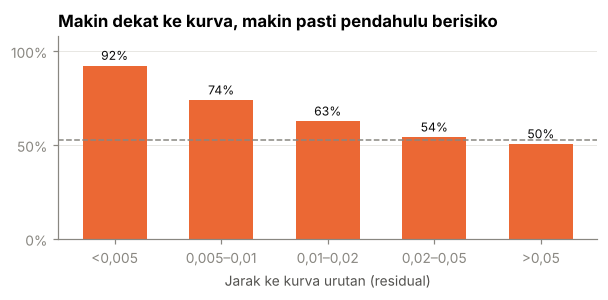

In [17]:
fig, ax = plt.subplots(figsize=(5.6, 2.8))
lab = ["<0,005", "0,005–0,01", "0,01–0,02", "0,02–0,05", ">0,05"]
b = ax.bar(lab, tab["proporsi berisiko"].values, color=C1, width=0.6)
ax.bar_label(b, labels=[f"{v:.0%}" for v in tab["proporsi berisiko"].values], padding=2, color=INK, fontsize=8)
ax.axhline(y.mean(), color=MUTED, lw=1, ls="--"); ax.set_ylim(0, 1.08); ax.grid(axis="x", visible=False)
ax.set_yticks([0, .5, 1]); ax.set_yticklabels(["0%", "50%", "100%"])
ax.set_xlabel("Jarak ke kurva urutan (residual)"); ax.set_title("Makin dekat ke kurva, makin pasti pendahulu berisiko")
plt.tight_layout(); plt.show()

Baris train yang penerusnya jatuh tepat di kurva hampir semuanya berisiko, sedangkan kandidat yang jauh dari kurva (kebetulan berprofil sama) sama saja dengan rata-rata. Ini mengonfirmasi bahwa tautannya nyata, dan residual dapat dipakai model sebagai ukuran keyakinan.

**Menyamakan kondisi train dengan test.** Fitur tautan baris test dihitung di dalam potongan berukuran ±10% data: kandidatnya jarang, dan posisi relatifnya lebih kasar daripada posisi di train. Jika model dilatih dengan fitur train yang dihitung dari seluruh train (80% data) lalu dipakai pada fitur test, artinya berbeda dan model salah kalibrasi.

Solusinya, baris train diberi perlakuan yang sama dengan baris test:

1. Baris train dikelompokkan menjadi **gugus mahasiswa**: pasangan yang saling menjadi kandidat terbaik dan dekat kurva digabung.
2. Tiap gugus dimasukkan secara acak ke salah satu dari 8 **potongan semu** (±10% data per potongan), sehingga — seperti di test — mahasiswa yang sama tetap berada di potongan yang sama.
3. Untuk tiap potongan semu, kurva dibentuk dari tujuh potongan lainnya dan kandidat dicari hanya di dalam potongan itu. Ini persis perlakuan untuk potongan test (kurva dari train, kandidat dalam potongan).

4. **Kalibrasi ulang per potongan.** Posisi relatif di potongan kecil berderau (hanya ±10% baris tiap blok), sehingga jarak ke kurva train ikut berderau. Padahal di dalam satu potongan, pasangan yang benar tetap membentuk rantai naik yang *persis*. Karena itu kandidat yang cukup dekat ke kurva train dirangkai lagi menjadi rantai naik terpanjang, dan jaraknya diukur ulang ke rantai potongan itu sendiri (`retake_min_res2`, `retake_on_chain`, dan padanannya untuk pendahulu).

Langkah 1 memakai posisi dan profil saja, tidak memakai label.

In [18]:
# 1) Gugus mahasiswa di train: pasangan yang saling menjadi kandidat terbaik dan dekat kurva
p = pairs_train[(pairs_train["res"] < 0.01) & (pairs_train["has_curve"] == 1)]
p = p[(p["res"] == p.groupby("row")["res"].transform("min")) & (p["res"] == p.groupby("row_s")["res"].transform("min"))]
parent = np.arange(N)
def find(a):
    while parent[a] != a:
        parent[a] = parent[parent[a]]; a = parent[a]
    return a
for a, b in zip(p["row"].values, p["row_s"].values):
    ra, rb = find(a), find(b)
    if ra != rb: parent[ra] = rb
cluster = np.array([find(i) for i in range(n_train)])

# 2) Tiap gugus masuk ke salah satu dari 8 potongan semu (seukuran potongan test)
N_CHUNK = 8
uniq = np.unique(cluster)
chunk_of = dict(zip(uniq, np.random.RandomState(SEED).randint(0, N_CHUNK, size=len(uniq))))
chunk = np.array([chunk_of[c] for c in cluster])

# 3) Fitur: test -> kurva dari train, kandidat hanya dalam potongan test yang sama;
#    train -> tiap potongan semu diperlakukan persis seperti potongan test
d_test = make_frame(np.where(SET > 0, SET, -1))
LINK = link_features(score_pairs_local(d_test, CURVES))
POS = np.full(N, np.nan); POS[d_test["row"].values] = d_test["pos"].values
for k in range(N_CHUNK):
    rest = np.full(N, -1); rest[:n_train] = np.where(chunk == k, -1, 0)
    part = np.full(N, -1); part[:n_train][chunk == k] = 0
    d_k = make_frame(part)
    F_k = link_features(score_pairs_local(d_k, fit_curves(make_frame(rest))))
    rows = d_k["row"].values
    LINK.loc[rows] = F_k.loc[rows]; POS[rows] = d_k["pos"].values
for c in ["retake_n_cand", "retake_n_close", "prev_n_cand", "retake_on_chain", "prev_on_chain"]: LINK[c] = LINK[c].fillna(0)
LINK["order_pos"] = POS            # posisi relatif baris dalam blok (dihitung dalam potongannya)
LINK_COLS = LINK.columns.tolist()

r = LINK["retake_min_res"]
cmp = pd.DataFrame({
    "train (potongan semu)": [r[~is_test].notna().mean()] + [(r[~is_test] < t).mean() for t in (.05, .10)],
    "test": [r[is_test].notna().mean()] + [(r[is_test] < t).mean() for t in (.05, .10)],
}, index=["porsi baris yang punya kandidat penerus", "porsi baris residual < 0,05", "porsi baris residual < 0,10"])
print(f"Gugus berisi >1 baris: {(pd.Series(cluster).value_counts() > 1).sum()} | proporsi berisiko train saat residual < 0,10: {y[(r[:n_train] < .10).values].mean():.3f}")
cmp.round(4)

Gugus berisi >1 baris: 935 | proporsi berisiko train saat residual < 0,10: 0.837


,train (potongan semu),test
porsi baris yang punya kandidat penerus,0.0617,0.0591
"porsi baris residual < 0,05",0.0351,0.0348
"porsi baris residual < 0,10",0.0445,0.0428


Porsi baris yang punya kandidat penerus dan sebaran residualnya di train (potongan semu) hampir sama dengan di test, jadi skor validasi silang dan threshold mencerminkan kondisi test. Fitur inilah yang dipakai untuk melatih model, ditambah `order_pos` (posisi relatif baris dalam bloknya).

In [19]:
full = pd.concat([treat_imputed(full_id).drop(columns=DROP_COLS), LINK], axis=1)
CAT_COLS = full.select_dtypes("object").columns.tolist()
NUM_COLS = [c for c in full.columns if c not in CAT_COLS]

# Dua representasi kategori: dtype category (LightGBM) dan kode ordinal (XGBoost, CatBoost).
# Daftar kategori diambil dari gabungan train+test agar pengkodeannya konsisten.
X_cat = full.copy()
for c in CAT_COLS: X_cat[c] = X_cat[c].astype("category")
X_ord = full.copy()
for c in CAT_COLS: X_ord[c] = X_ord[c].astype("category").cat.codes

for c in CAT_COLS:
    assert set(full[c][n_train:]) <= set(full[c][:n_train]), c
print("Jumlah fitur:", full.shape[1], "| kategorikal:", len(CAT_COLS), "| numerik:", len(NUM_COLS))
print("Semua kategori di test sudah ada di train.")

Jumlah fitur: 74 | kategorikal: 8 | numerik: 66
Semua kategori di test sudah ada di train.


## 4. Pemilihan Model

**Skema validasi:** Stratified 5-fold, seed tetap. Setiap model menghasilkan prediksi *out-of-fold* (OOF) untuk seluruh data train, sehingga semua model dibandingkan pada data yang tidak dilihatnya saat latihan.

**Kandidat:**

| Model | Alasan |
|---|---|
| Logistic Regression | Baseline linear, pembanding sederhana |
| LightGBM | Gradient boosting, menangani kategori secara native |
| XGBoost | Gradient boosting dengan regularisasi berbeda |
| CatBoost | Pohon simetris, cenderung stabil |
| Blend | Rata-rata probabilitas tiga model boosting |

Model boosting memakai *early stopping* pada fold validasi. Setiap model boosting dilatih dengan 3 seed (`SEEDS`); prediksi OOF dan test adalah rata-rata 5 model fold × 3 seed, agar hasil tidak bergantung pada satu seed.

In [20]:
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = list(skf.split(np.zeros(n_train), y))

def fit_logreg(Xa, ya, Xb, yb, Xt, seed=SEED):
    num = make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler())   # NaN: tidak ada tautan / nilai imputasi
    pre = ColumnTransformer([("num", num, NUM_COLS), ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS)])
    m = make_pipeline(pre, LogisticRegression(C=1.0, max_iter=2000, random_state=seed)).fit(Xa, ya)
    return m.predict_proba(Xb)[:, 1], m.predict_proba(Xt)[:, 1], None

def fit_lgb(Xa, ya, Xb, yb, Xt, seed=SEED):
    m = lgb.LGBMClassifier(n_estimators=3000, learning_rate=0.02, num_leaves=15, min_child_samples=60,
                           subsample=0.8, subsample_freq=1, colsample_bytree=0.4, reg_lambda=10,
                           random_state=seed, n_jobs=N_JOBS, deterministic=True, force_row_wise=True, verbose=-1)
    m.fit(Xa, ya, eval_set=[(Xb, yb)], callbacks=[lgb.early_stopping(150, verbose=False)])
    return m.predict_proba(Xb)[:, 1], m.predict_proba(Xt)[:, 1], m

def fit_xgb(Xa, ya, Xb, yb, Xt, seed=SEED):
    m = xgb.XGBClassifier(n_estimators=3000, learning_rate=0.02, max_depth=5, min_child_weight=5,
                          subsample=0.8, colsample_bytree=0.4, reg_lambda=5, tree_method="hist",
                          early_stopping_rounds=150, random_state=seed, n_jobs=N_JOBS)
    m.fit(Xa, ya, eval_set=[(Xb, yb)], verbose=False)
    return m.predict_proba(Xb)[:, 1], m.predict_proba(Xt)[:, 1], m

def fit_cat(Xa, ya, Xb, yb, Xt, seed=SEED):
    m = CatBoostClassifier(iterations=3000, learning_rate=0.05, depth=6, early_stopping_rounds=150,
                           random_seed=seed, thread_count=N_JOBS, verbose=0)
    m.fit(Xa, ya, eval_set=(Xb, yb))
    return m.predict_proba(Xb)[:, 1], m.predict_proba(Xt)[:, 1], m

def run_cv(name, fit_fn, X, seeds=SEEDS):
    # tiap seed: 5 model fold; OOF dan prediksi test dirata-ratakan antar-seed
    t0 = time.time()
    Xtr, Xte = X.iloc[:n_train], X.iloc[n_train:]
    oof, pred, models = np.zeros(n_train), np.zeros(len(Xte)), []
    for s in seeds:
        for a, b in folds:
            p_val, p_test, m = fit_fn(Xtr.iloc[a], y[a], Xtr.iloc[b], y[b], Xte, seed=s)
            oof[b] += p_val / len(seeds); pred += p_test / (N_FOLDS * len(seeds)); models.append(m)
    print(f"{name:20s} AUC OOF = {roc_auc_score(y, oof):.5f}   ({time.time() - t0:.0f} dtk)")
    return oof, pred, models

OOF, PRED, MODELS = {}, {}, {}
for name, fn, X in [("Logistic Regression", fit_logreg, full), ("LightGBM", fit_lgb, X_cat),
                    ("XGBoost", fit_xgb, X_ord), ("CatBoost", fit_cat, X_ord)]:
    OOF[name], PRED[name], MODELS[name] = run_cv(name, fn, X)

BLEND = ["LightGBM", "XGBoost", "CatBoost"]
OOF["Blend (LGB+XGB+CAT)"] = np.mean([OOF[m] for m in BLEND], axis=0)
PRED["Blend (LGB+XGB+CAT)"] = np.mean([PRED[m] for m in BLEND], axis=0)

Logistic Regression  AUC OOF = 0.84367   (36 dtk)


LightGBM             AUC OOF = 0.85370   (50 dtk)


XGBoost              AUC OOF = 0.85344   (89 dtk)


CatBoost             AUC OOF = 0.85280   (56 dtk)


In [21]:
THRESHOLDS = np.round(np.arange(0.20, 0.701, 0.01), 2)

def f1_curve(p):
    return np.array([f1_score(y, p > t) for t in THRESHOLDS])

rows = []
for name, p in OOF.items():
    fc = f1_curve(p)
    rows.append({"model": name, "AUC": roc_auc_score(y, p), "F1 @0.50": f1_score(y, p > 0.5),
                 "F1 terbaik": fc.max(), "threshold terbaik": THRESHOLDS[fc.argmax()]})
results = pd.DataFrame(rows).set_index("model").sort_values("F1 terbaik", ascending=False)
results.round(5)

,AUC,F1 @0.50,F1 terbaik,threshold terbaik
model,,,,
Blend (LGB+XGB+CAT),0.85415,0.77111,0.78017,0.38
CatBoost,0.85280,0.76878,0.77946,0.36
XGBoost,0.85344,0.77003,0.77910,0.38
LightGBM,0.85370,0.77239,0.77879,0.39
Logistic Regression,0.84367,0.76178,0.77268,0.37


Cara membaca tabel: `AUC` mengukur kualitas pengurutan probabilitas, `F1 @0.50` adalah F1 dengan threshold bawaan, dan `F1 terbaik` adalah F1 pada threshold optimal di data OOF.

**Model terpilih: blend LightGBM + XGBoost + CatBoost.** Ketiga model boosting mengungguli baseline linear, dan rata-rata ketiganya memberi AUC dan F1 OOF tertinggi sekaligus lebih stabil daripada satu model tunggal. Selisih antarmodel boosting kecil, yang menunjukkan skor sudah mendekati batas informasi yang tersedia di fitur.

## 5. Evaluasi Model

### 5.1 Optimasi threshold

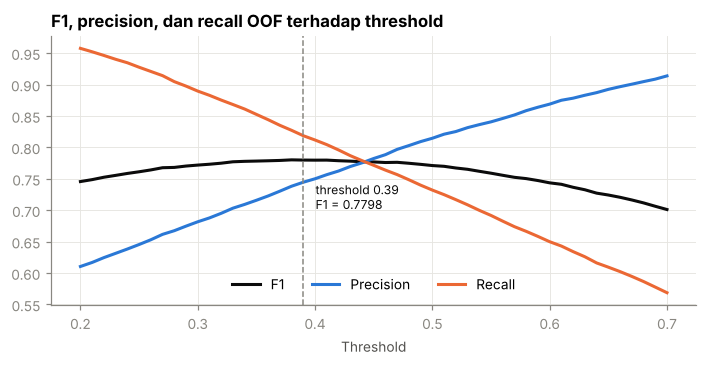

Threshold terpilih: 0.39
F1 OOF @ 0.39 = 0.77983   |   maksimum mentah = 0.78017 @ 0.38   |   F1 OOF @ 0.50 = 0.77111
Rentang threshold dengan F1 dalam 0,001 dari maksimum: 0.37 - 0.41


In [22]:
FINAL = "Blend (LGB+XGB+CAT)"
oof_final, pred_final = OOF[FINAL], PRED[FINAL]

fc = f1_curve(oof_final)
fc_smooth = np.convolve(np.pad(fc, 2, mode="edge"), np.ones(5) / 5, mode="valid")   # rata-rata bergerak 5 titik
BEST_T = float(THRESHOLDS[fc_smooth.argmax()])
F1_AT_T = float(fc[fc_smooth.argmax()])
prec = [precision_score(y, oof_final > t) for t in THRESHOLDS]
rec = [recall_score(y, oof_final > t) for t in THRESHOLDS]

fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(THRESHOLDS, fc, color=INK, lw=2, label="F1")
ax.plot(THRESHOLDS, prec, color=C0, lw=2, label="Precision")
ax.plot(THRESHOLDS, rec, color=C1, lw=2, label="Recall")
ax.axvline(BEST_T, color=MUTED, lw=1, ls="--")
ax.annotate(f"threshold {BEST_T:.2f}\nF1 = {F1_AT_T:.4f}", (BEST_T, F1_AT_T), xytext=(8, -32), textcoords="offset points", color=INK, fontsize=8)
ax.set_xlabel("Threshold"); ax.set_title("F1, precision, dan recall OOF terhadap threshold"); ax.legend(frameon=False, ncol=3, loc="lower center")
plt.tight_layout(); plt.show()

print(f"Threshold terpilih: {BEST_T:.2f}")
print(f"F1 OOF @ {BEST_T:.2f} = {F1_AT_T:.5f}   |   maksimum mentah = {fc.max():.5f} @ {THRESHOLDS[fc.argmax()]:.2f}   |   F1 OOF @ 0.50 = {f1_score(y, oof_final > 0.5):.5f}")
near = THRESHOLDS[fc >= fc.max() - 0.001]
print(f"Rentang threshold dengan F1 dalam 0,001 dari maksimum: {near.min():.2f} - {near.max():.2f}")

F1 kelas positif maksimal pada threshold di bawah 0,5: menurunkan threshold menaikkan recall lebih banyak daripada turunnya precision. Kurva F1 landai di sekitar puncaknya, sehingga titik maksimum mentahnya mudah bergeser oleh derau. Karena itu threshold diambil dari kurva F1 yang **dihaluskan** (rata-rata bergerak 5 titik), yaitu tengah dari dataran puncak.

### 5.2 Kestabilan antar-fold dan matriks kebingungan

In [23]:
fold_f1 = [f1_score(y[b], oof_final[b] > BEST_T) for _, b in folds]
fold_auc = [roc_auc_score(y[b], oof_final[b]) for _, b in folds]
print("F1 per fold :", np.round(fold_f1, 4), f"-> rata-rata {np.mean(fold_f1):.4f} ± {np.std(fold_f1):.4f}")
print("AUC per fold:", np.round(fold_auc, 4), f"-> rata-rata {np.mean(fold_auc):.4f} ± {np.std(fold_auc):.4f}")

oof_label = (oof_final > BEST_T).astype(int)
cm = confusion_matrix(y, oof_label)
print("\nMatriks kebingungan (baris = aktual, kolom = prediksi):")
display(pd.DataFrame(cm, index=["aktual 0", "aktual 1"], columns=["prediksi 0", "prediksi 1"]))
print(classification_report(y, oof_label, digits=4, target_names=["0 — tidak berisiko", "1 — berisiko"]))

F1 per fold : [0.7762 0.7852 0.7826 0.7702 0.785 ] -> rata-rata 0.7798 ± 0.0058
AUC per fold: [0.851  0.8627 0.8556 0.8464 0.8552] -> rata-rata 0.8542 ± 0.0054

Matriks kebingungan (baris = aktual, kolom = prediksi):


,prediksi 0,prediksi 1
aktual 0,8471,3862
aktual 1,2495,11258


                    precision    recall  f1-score   support

0 — tidak berisiko     0.7725    0.6869    0.7272     12333
      1 — berisiko     0.7446    0.8186    0.7798     13753

          accuracy                         0.7563     26086
         macro avg     0.7585    0.7527    0.7535     26086
      weighted avg     0.7578    0.7563    0.7549     26086



### 5.3 Performa per modul

In [24]:
mod = full["code_module"].iloc[:n_train].values
rows = []
for m in sorted(set(mod)):
    k = mod == m
    rows.append({"modul": m, "n": int(k.sum()), "proporsi berisiko": y[k].mean(), "F1": f1_score(y[k], oof_label[k]), "AUC": roc_auc_score(y[k], oof_final[k])})
per_mod = pd.DataFrame(rows).set_index("modul")
per_mod.round(4)

,n,proporsi berisiko,F1,AUC
modul,,,,
M01,602,0.3040,0.5836,0.7959
M02,6368,0.5231,0.7692,0.8481
M03,3568,0.6200,0.8390,0.8791
M04,6159,0.5259,0.7836,0.8579
M05,2342,0.4394,0.7253,0.8397
M06,5066,0.5825,0.8240,0.8757
M07,1981,0.4079,0.5923,0.6990


Modul `M07` penting diperhatikan: baris `GGG` di data test dipetakan ke modul ini, dan 145 baris train yang kodenya terselip juga dikembalikan ke sini. Modul ini paling sulit diprediksi karena pada 4 minggu pertama belum ada nilai asesmen dan aktivitas daringnya sedikit.

### 5.4 Fitur terpenting

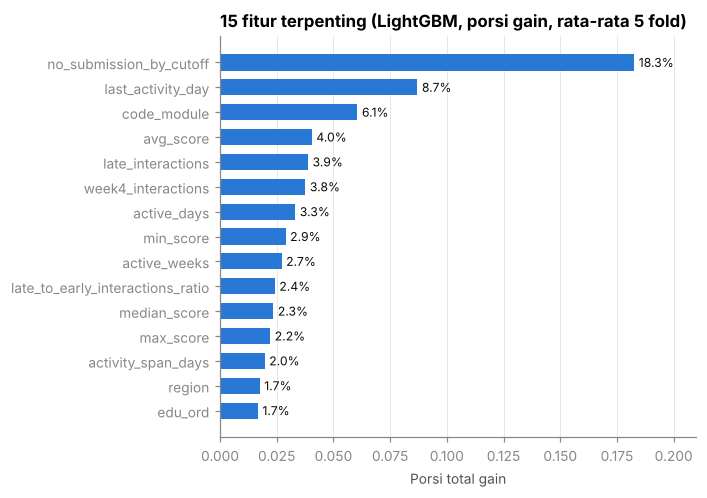

In [25]:
imp = pd.DataFrame({i: pd.Series(m.booster_.feature_importance("gain"), index=X_cat.columns) for i, m in enumerate(MODELS["LightGBM"])})
imp = (imp / imp.sum()).mean(axis=1).sort_values().tail(15)

fig, ax = plt.subplots(figsize=(6.5, 4.6))
b = ax.barh(imp.index, imp.values, color=C0, height=0.65)
ax.bar_label(b, labels=[f"{v:.1%}" for v in imp.values], padding=3, color=INK, fontsize=8)
ax.set_xlim(0, imp.max() * 1.15); ax.grid(axis="y", visible=False)
ax.set_title("15 fitur terpenting (LightGBM, porsi gain, rata-rata 5 fold)"); ax.set_xlabel("Porsi total gain")
plt.tight_layout(); plt.show()

### 5.5 Kontribusi fitur tautan (ablasi)

In [26]:
X_no = X_cat.drop(columns=LINK_COLS)
oof_no, _, _ = run_cv("LightGBM tanpa tautan", fit_lgb, X_no)
abl = pd.DataFrame({
    "AUC": [roc_auc_score(y, oof_no), roc_auc_score(y, OOF["LightGBM"])],
    "F1 terbaik": [f1_curve(oof_no).max(), f1_curve(OOF["LightGBM"]).max()],
}, index=["LightGBM tanpa fitur tautan", "LightGBM dengan fitur tautan"])

strong = (LINK_SHARP.retake_min_res[:n_train] < 0.005).values
print(f"Baris train dengan tautan kuat: {strong.sum()} | aktual berisiko {y[strong].mean():.1%}")
print(f"  diprediksi tidak berisiko — tanpa tautan: {(oof_no[strong] <= BEST_T).mean():.1%} | dengan tautan: {(OOF['LightGBM'][strong] <= BEST_T).mean():.1%}")
abl.round(5)

LightGBM tanpa tautan AUC OOF = 0.84744   (34 dtk)


Baris train dengan tautan kuat: 871 | aktual berisiko 92.2%
  diprediksi tidak berisiko — tanpa tautan: 21.9% | dengan tautan: 4.1%


,AUC,F1 terbaik
LightGBM tanpa fitur tautan,0.84744,0.77473
LightGBM dengan fitur tautan,0.85370,0.77879


Kenaikan datang dari sekelompok kecil mahasiswa yang sebelumnya diprediksi aman padahal kemudian mengulang modul. Di luar kelompok itu perilaku model tidak berubah.

## 6. Prediksi Data Test & File Submission

Probabilitas test adalah rata-rata 5 model fold × 3 seed dari tiap algoritma, lalu dirata-ratakan antar-algoritma dan dipotong dengan threshold hasil OOF.

In [27]:
submission = pd.DataFrame({"id": test["id"].values, TARGET: (pred_final > BEST_T).astype(int)})

assert list(submission.columns) == list(sample_sub.columns)
assert len(submission) == len(sample_sub) and (submission["id"].values == sample_sub["id"].values).all()
assert submission["id"].is_unique and set(submission[TARGET]) <= {0, 1}

out_path = f"{OUT_DIR}submission_{SUBMISSION_NO}.csv"
submission.to_csv(out_path, index=False)

print("Tersimpan:", out_path, "|", submission.shape)
print(f"Proporsi prediksi berisiko — test: {submission[TARGET].mean():.4f} | OOF train: {oof_label.mean():.4f} | label train: {y.mean():.4f}")
print(f"Rata-rata probabilitas — test: {pred_final.mean():.4f} | OOF train: {oof_final.mean():.4f}")
submission.head()

Tersimpan: ../submissions/submission_5.csv | (6502, 2)
Proporsi prediksi berisiko — test: 0.5792 | OOF train: 0.5796 | label train: 0.5272
Rata-rata probabilitas — test: 0.5279 | OOF train: 0.5273


,id,at_risk
0,26092,0
1,26093,0
2,26094,0
3,26095,0
4,26096,1


## 7. Insight Preskriptif

Berdasarkan EDA dan fitur terpenting model:

1. **Asesmen pertama adalah sinyal paling tegas.** Mahasiswa yang tidak mengumpulkan asesmen sampai batas waktu hampir pasti berisiko (≈94%). Rekomendasi: pengingat otomatis sebelum tenggat dan kontak langsung dari tutor dalam 48 jam setelah tenggat terlewat.
2. **Keterlibatan 4 minggu pertama menentukan.** Hari aktif dan volume interaksi yang rendah berkaitan erat dengan risiko; mahasiswa yang **sama sekali tidak membuka VLE** selama 4 minggu pertama (±14% mahasiswa) 95% berisiko. Rekomendasi: pantau keaktifan mingguan dan hubungi mahasiswa yang belum pernah login sejak minggu ke-1–2, jangan menunggu asesmen.
3. **Beban studi dan riwayat mengulang.** Risiko naik seiring jumlah SKS dan jumlah percobaan sebelumnya. Rekomendasi: konseling beban studi saat registrasi dan pendampingan khusus bagi mahasiswa yang mengulang.
4. **Risiko berbeda antarmodul.** Modul dengan proporsi berisiko tinggi layak ditinjau desain awal dan beban asesmennya.
5. **Mengulang modul adalah pola yang terlihat di data.** Sebagian mahasiswa berisiko kembali mendaftar di presentasi berikutnya. Rekomendasi: saat pendaftaran ulang, tawarkan jalur pendampingan sejak minggu pertama, karena kelompok ini sudah terbukti pernah gagal di modul yang sama.

**Batasan fitur tautan.** Fitur tautan memakai data presentasi berikutnya, jadi berguna untuk analisis retrospektif dan untuk kompetisi ini, tetapi untuk sistem peringatan dini yang berjalan di minggu ke-4 yang dipakai adalah model tanpa fitur tersebut (lihat 5.5).

**Pemakaian skor model:** probabilitas dapat dipakai untuk memprioritaskan intervensi — kelompok probabilitas tertinggi dihubungi tutor secara personal, kelompok menengah diberi pengingat otomatis. Threshold yang rendah sengaja mengutamakan recall: lebih baik menghubungi mahasiswa yang ternyata aman daripada melewatkan yang benar-benar berisiko.